# Scout churn model (synthetic data)

A walkthrough of `coursework/churn/`, with steps matching `NOTES.md` [N1]…[N10]. **All Scouts are synthetic** (live-sim's `data/live_sim.db`, seed 42, when present; otherwise the marked stand-in). Run `bash coursework/run_coursework.sh` first; this notebook reads its outputs and calls the same functions.

In [1]:
# Find the repo root (the folder that contains coursework/) and make it importable.
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / "coursework").is_dir():
    root = root.parent
sys.path.insert(0, str(root)); os.chdir(root)
print("repo root:", root)

repo root: /home/user/manhattan-bars-ml


## Load the tables (live_sim.db if present, else the marked stand-in CSVs)

In [2]:
from coursework.churn.load import load
# SYNTHETIC: replace with the real backend tables
data = load()
print('source:', data['source'])
for k in ['scouts', 'reports', 'ledger', 'bounties', 'rep_history']:
    print(f'{k:12s}', len(data[k]))

source: db
scouts       209
reports      8147
ledger       17702
bounties     2409
rep_history  1644


## [N2]–[N3] Two snapshots: features before the cutoff, label in the 21 days after

In [3]:
from coursework.churn.build_dataset import build, FEATURES, TRAIN_CUTOFF, TEST_CUTOFF
train, test = build(data, TRAIN_CUTOFF), build(data, TEST_CUTOFF)
for name, df in [('train', train), ('test', test)]:
    print(f'{name}: {len(df)} Scouts, base rate {df.churned.mean():.1%}')
train.head()

train: 86 Scouts, base rate 31.4%
test: 101 Scouts, base rate 40.6%


,scout_id,cutoff,tenure_days,cohort_week,reports_28d,reports_7d,days_since_last_report,active_nights_28d,mean_gap_days,trend,...,distinct_venues_28d,share_saturday_reports,points_28d,points_total,bounties_claimed_28d,reputation_asof,points_asof,level_asof,churned,is_synthetic
0,syn-s-0001,2026-10-01,36.810417,0,35,4,5.427870,8,2.900000,-6.333333,...,15,0.339623,1035,1460,11,0.6350,1460,3,1,1
1,syn-s-0002,2026-10-01,34.805556,0,51,10,4.479479,12,2.230769,-3.666667,...,25,0.348485,1710,2050,20,0.4563,2050,4,0,1
2,syn-s-0003,2026-10-01,34.668056,0,44,8,4.393345,8,3.000000,-4.000000,...,16,0.540984,1095,1575,10,0.4946,1575,4,0,1
3,syn-s-0005,2026-10-01,34.721528,0,45,14,4.484745,8,3.000000,3.666667,...,22,0.518519,1060,1360,9,0.5575,1360,3,0,1
4,syn-s-0006,2026-10-01,37.752083,0,39,4,5.507870,8,3.375000,-7.666667,...,18,0.454545,785,900,4,0.5558,900,3,1,1


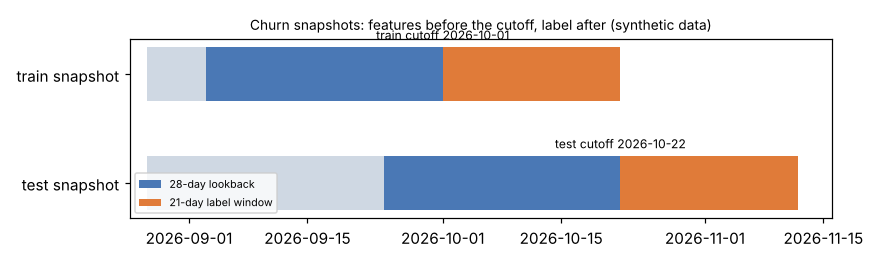

In [4]:
from IPython.display import Image, display
display(Image('coursework/churn/outputs/timeline.png'))

## [N4] Leakage check: delete everything after the cutoff, the features must not change

In [5]:
import pandas as pd
cut = pd.Timestamp(f'{TRAIN_CUTOFF} 12:00', tz='America/New_York')
trimmed = dict(data, reports=data['reports'][data['reports'].ts < cut], ledger=data['ledger'][data['ledger'].ts < cut])
print('features identical:', build(trimmed, TRAIN_CUTOFF)[FEATURES].equals(train[FEATURES]))

features identical: True


## [N5]–[N8] Results: 5 models, CV on train, one out-of-time test (from `outputs/metrics.json`)

In [6]:
import json
m = json.loads(Path('coursework/churn/outputs/metrics.json').read_text())
rows = [{'model': n, 'settings': r['params'], 'cv_auc': round(r['cv_auc_mean'], 3), 'test_auc': round(r['test']['roc_auc'], 3),
         'test_auc_ci': [round(v, 2) for v in r['test_roc_auc_ci']], 'test_pr_auc': round(r['test']['pr_auc'], 3),
         'base_rate': round(r['test']['base_rate'], 3), 'brier': round(r['test']['brier'], 3), 'f1': round(r['test']['f1'], 2)}
        for n, r in m['models'].items()]
print('selected by CV:', m['selected_model'])
pd.DataFrame(rows)

selected by CV: logistic


,model,settings,cv_auc,test_auc,test_auc_ci,test_pr_auc,base_rate,brier,f1
0,majority,{},0.500,0.500,"[0.5, 0.5]",0.406,0.406,0.406,0.58
1,logistic,{'C': 0.1},0.887,0.852,"[0.77, 0.92]",0.780,0.406,0.148,0.74
2,tree,{'max_depth': 4},0.811,0.788,"[0.71, 0.87]",0.646,0.406,0.204,0.72
3,forest,{'min_samples_leaf': 20},0.883,0.864,"[0.79, 0.93]",0.846,0.406,0.165,0.75
4,boosting,{'learning_rate': 0.1},0.859,0.840,"[0.76, 0.91]",0.787,0.406,0.167,0.72


## [N6] Logistic regression odds ratios (per +1 SD), refit live

In [7]:
from coursework.churn.train_eval import make_model
from coursework.churn.explain import odds_ratio_table
lr = make_model('logistic', m['models']['logistic']['params']).fit(train[FEATURES], train.churned)
odds_ratio_table(lr).head(8)

,feature,coef_per_sd,odds_ratio_per_sd
3,reports_7d,-0.438474,0.645020
7,trend,-0.339795,0.711916
13,points_28d,-0.273458,0.760744
15,bounties_claimed_28d,-0.254405,0.775377
1,cohort_week,-0.245037,0.782675
4,days_since_last_report,0.238947,1.269911
2,reports_28d,-0.210152,0.810461
14,points_total,-0.185574,0.830627


## [N7] The shallow tree as text

In [8]:
from sklearn.tree import export_text
tree = make_model('tree', m['models']['tree']['params']).fit(train[FEATURES], train.churned)
print(export_text(tree[-1], feature_names=FEATURES, decimals=1, show_weights=True))

|--- reports_7d <= 6.5
|   |--- reports_28d <= 35.5
|   |   |--- share_saturday_reports <= 0.7
|   |   |   |--- points_28d <= 615.0
|   |   |   |   |--- weights: [1.5, 31.9] class: 1
|   |   |   |--- points_28d >  615.0
|   |   |   |   |--- weights: [2.2, 3.2] class: 1
|   |   |--- share_saturday_reports >  0.7
|   |   |   |--- weights: [2.9, 3.2] class: 1
|   |--- reports_28d >  35.5
|   |   |--- weights: [4.4, 1.6] class: 0
|--- reports_7d >  6.5
|   |--- share_saturday_reports <= 0.5
|   |   |--- weights: [29.9, 0.0] class: 0
|   |--- share_saturday_reports >  0.5
|   |   |--- weights: [2.2, 3.2] class: 1



## [N8]–[N9] Curves, calibration, importance and the targeting view

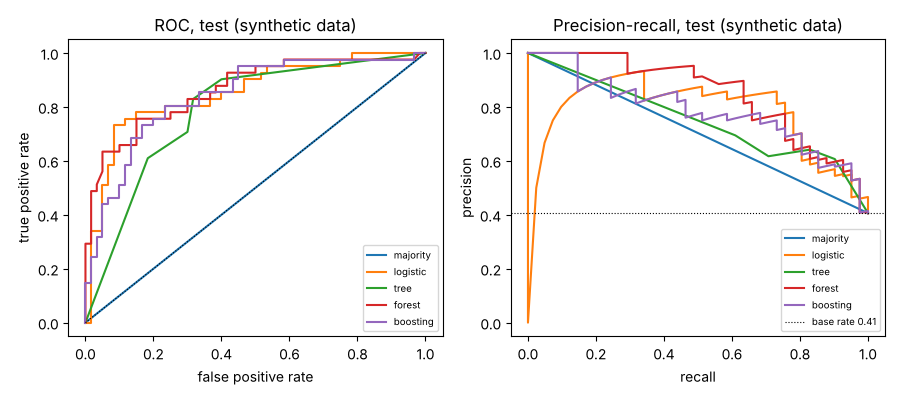

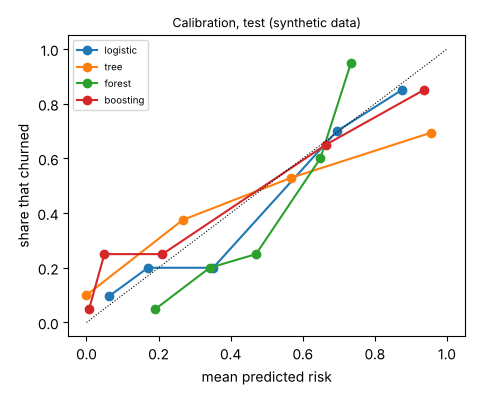

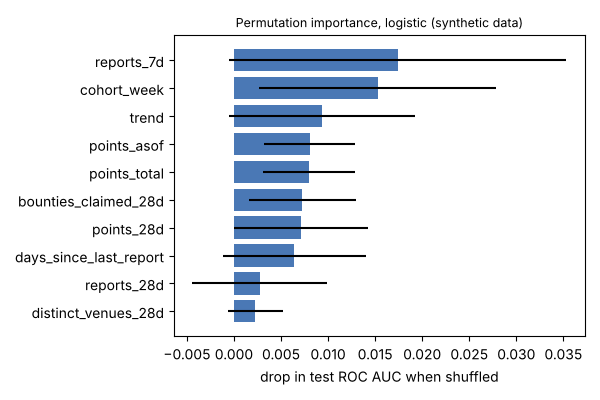

In [9]:
for png in ['roc_pr_test', 'calibration_test', 'permutation_importance']:
    display(Image(f'coursework/churn/outputs/{png}.png'))

In [10]:
from coursework.churn.explain import top_risk_table
top_risk_table(lr, test)

,riskiest share,scouts,churned,churn rate,lift vs base
0,10%,10,9,0.90,2.217073
1,25%,25,21,0.84,2.069268
2,50%,50,33,0.66,1.625854


## Evaluation-only truth check and limitations

See the last section of `outputs/report.md` (written by `evaluate_truth.py`, the only file that reads the simulator's truth table) and `NOTES.md` [N10].